# 第 6 章 再谈马尔可夫链蒙特卡罗 — 代码实验

对照教材：Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》第 6 章（§6.1–6.4）。

11 个实验，输出图 `out-6-M.png`。随机种子 2029。

In [1]:
# ===== 公共设置 =====
import numpy as np
import matplotlib.pyplot as plt
from math import log, sqrt, pi, comb, factorial
from pathlib import Path

rng = np.random.default_rng(2029)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch06")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 硬币问题：MLE vs 贝叶斯（书 §6.1，式 (6.1)）

7/10 的观测：MLE = 0.7；离散先验（90% 信 50/50）被推到后验 20.191%。

P(obs|θ7/30)=0.26683, P(obs|θ5/50)=0.11719
后验 Pr(70/30 币) = 0.20191（书 0.20191）


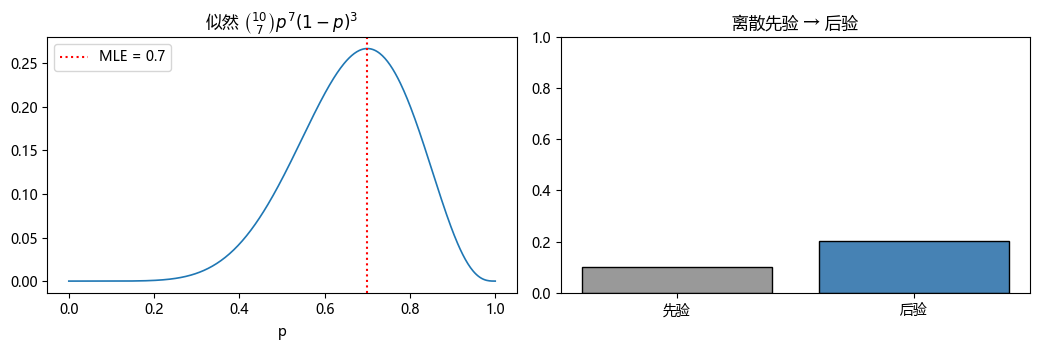

In [2]:
# ===== 书 §6.1 式 (6.1) =====
ps = np.linspace(0, 1, 500)
lik = np.array([comb(10, 7)*p**7*(1-p)**3 for p in ps])
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].plot(ps, lik, lw=1.2)
ax[0].axvline(0.7, ls=":", color="r", label="MLE = 0.7")
ax[0].set_title(r"似然 $\binom{10}{7}p^7(1-p)^3$"); ax[0].set_xlabel("p"); ax[0].legend()
# 离散贝叶斯更新
L0, L7 = comb(10, 7)*0.5**10, comb(10, 7)*0.7**7*0.3**3
post = L7*0.1/(L7*0.1 + L0*0.9)
print(f"P(obs|θ7/30)={L7:.5f}, P(obs|θ5/50)={L0:.5f}")
print(f"后验 Pr(70/30 币) = {post:.5f}（书 0.20191）")
ax[1].bar(["先验", "后验"], [0.1, post], color=["0.6", "steelblue"], edgecolor="k")
ax[1].set_ylim(0, 1); ax[1].set_title("离散先验 → 后验")
plt.tight_layout(); save(fig, "out-6-1.png"); plt.show()

## 实验 2 共轭：Beta 先验 + Poisson-Gamma（书 §6.1，式 (6.2)(6.3)；习题 1）

左：Be(3,3) 先验 ×7/10 → Be(10,6)；MAP 与后验预测。右：Gamma 先验 + Poisson 似然 → Gamma 后验（参数自证）。

后验预测 Pr(heads) = 10/16 = 0.625（式 6.3，对 θ 平均）


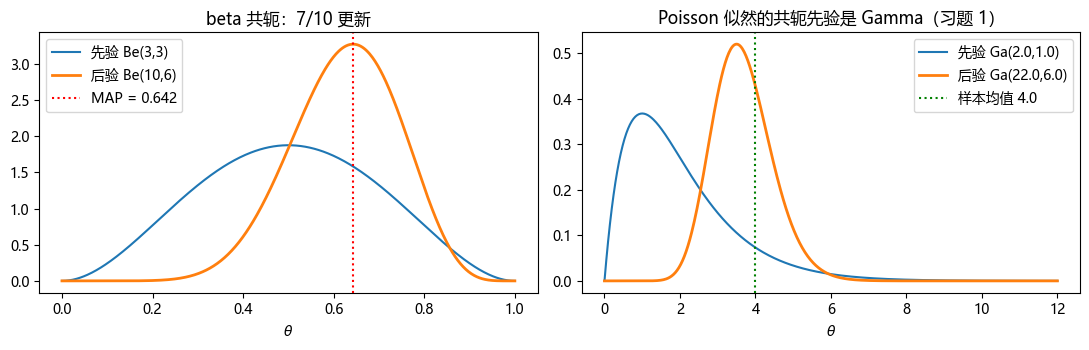

后验参数：α' = α+Σx = 22.0，β' = β+n = 6.0（闭式更新）


In [3]:
# ===== 书 §6.1 共轭 =====
from scipy import stats as st
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
th = np.linspace(0, 1, 500)
ax[0].plot(th, st.beta(3, 3).pdf(th), label="先验 Be(3,3)")
ax[0].plot(th, st.beta(10, 6).pdf(th), lw=2, label="后验 Be(10,6)")
ax[0].axvline(0.642, ls=":", color="r", label="MAP = 0.642")
ax[0].set_title("beta 共轭：7/10 更新"); ax[0].set_xlabel(r"$\theta$"); ax[0].legend()
print(f"后验预测 Pr(heads) = 10/16 = {10/16}（式 6.3，对 θ 平均）")
# Poisson-Gamma：先验 Ga(α=2, rate=1)，观测 x=(3,4,3,5,5)（书习题 3 数据量级）
al, be = 2.0, 1.0
data = np.array([3, 4, 3, 5, 5])
al_p, be_p = al + data.sum(), be + len(data)
xs2 = np.linspace(0, 12, 500)
ax[1].plot(xs2, st.gamma(al, scale=1/be).pdf(xs2), label=f"先验 Ga({al},{be})")
ax[1].plot(xs2, st.gamma(al_p, scale=1/be_p).pdf(xs2), lw=2,
           label=f"后验 Ga({al_p},{be_p})")
ax[1].axvline(data.mean(), ls=":", color="g", label=f"样本均值 {data.mean()}")
ax[1].set_title("Poisson 似然的共轭先验是 Gamma（习题 1）"); ax[1].set_xlabel(r"$\theta$"); ax[1].legend()
plt.tight_layout(); save(fig, "out-6-2.png"); plt.show()
print(f"后验参数：α' = α+Σx = {al_p}，β' = β+n = {be_p}（闭式更新）")

## 实验 3（并入实验 2）：MAP 的解析核

无共轭时丢常数直接最大化 \(\\Pr(\\text{obs}|\\theta)\\Pr(\\theta)\)—— pizza 例（习题 3）的核函数图。

pizza 例 MAP ≈ 4.56（直接最大化 未归一化后验核）


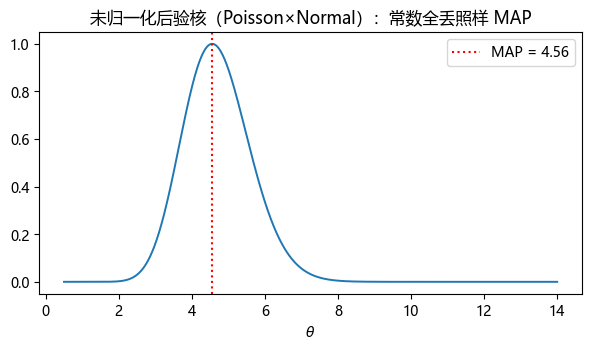

In [4]:
# ===== 习题 3 pizza：Poisson 似然 × Normal(7,2) 先验，无共轭 =====
obs = np.array([3, 4, 3, 5, 5])
th = np.linspace(0.5, 14, 800)
def loglik(t): return np.sum(obs*log(t)) - obs.size*t        # 丢常数项
def logprior(t): return -0.5*((t-7)/2)**2                    # N(7,2)
core = np.array([loglik(t)+logprior(t) for t in th])
core -= core.max()
map_hat = th[np.argmax(core)]
print(f"pizza 例 MAP ≈ {map_hat:.2f}（直接最大化 未归一化后验核）")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(th, np.exp(core), lw=1.4)
ax.axvline(map_hat, ls=":", color="r", label=f"MAP = {map_hat:.2f}")
ax.set_title("未归一化后验核（Poisson×Normal）：常数全丢照样 MAP")
ax.set_xlabel(r"$\theta$"); ax.legend()
save(fig, "out-6-3.png"); plt.show()

## 实验 4 小麦生长的 MCMC 后验（书 §6.1，Alg 6.1，Fig 6.2/6.3）

先验 N(0.20, 0.04²)；似然：5 点偏差 ~ N(0, 0.06)。Metropolis 采样后验。

后验均值 0.3187，方差 0.00041（书 0.32 / 0.0004）


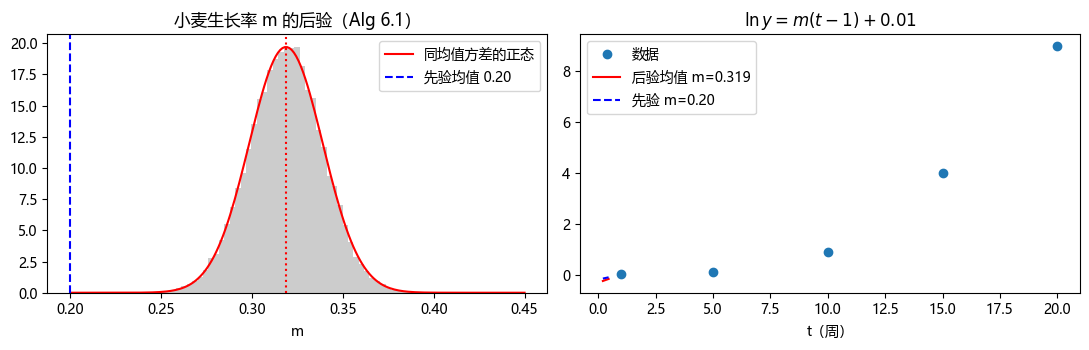

In [5]:
# ===== 书 §6.1 Alg 6.1 =====
tdat = np.array([1., 5., 10., 15., 20.])
ydat = np.array([.01, 0.1, 0.9, 4., 9.])
mu_m, sigma_m, sigma_l = 0.20, 0.04, 0.6   # 书 Alg 6.1 代码用 0.6（正文印 0.06，见勘误）
def lny(t, m): return m*(t-1) + 0.01
def fpost(m):
    ss = np.sum((ydat - lny(tdat, m))**2)
    return np.exp(-0.5*((m-mu_m)/sigma_m)**2) * np.exp(-ss/(2*sigma_l**2))
def propose(x):                      # 保持 [0,1] 的反射提案
    y = x + 0.05*rng.uniform(-1, 1)
    return -y if y < 0 else (2-y if y > 1 else y)
x = rng.normal(mu_m, sigma_m); fx = fpost(x)
trace = []
for i in range(110_000):
    y = propose(x); fy = fpost(y)
    if rng.random() < fy/fx: x, fx = y, fy
    if i > 10_000: trace.append(x)
trace = np.array(trace)
print(f"后验均值 {trace.mean():.4f}，方差 {trace.var():.5f}（书 0.32 / 0.0004）")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(trace, bins=60, density=True, color="0.8", edgecolor="none")
mm = np.linspace(0.2, 0.45, 200)
ax[0].plot(mm, np.exp(-0.5*((mm-trace.mean())/np.sqrt(trace.var()))**2)
           /np.sqrt(2*pi*trace.var()), "r-", lw=1.5, label="同均值方差的正态")
ax[0].axvline(mu_m, ls="--", color="b", label="先验均值 0.20")
ax[0].axvline(trace.mean(), ls=":", color="r")
ax[0].set_title("小麦生长率 m 的后验（Alg 6.1）"); ax[0].set_xlabel("m"); ax[0].legend()
ax[1].plot(tdat, ydat, "o", ms=6, label="数据")
ax[1].plot(mm, 0.01 + trace.mean()*(mm-1), "r-", label=f"后验均值 m={trace.mean():.3f}")
ax[1].plot(mm, 0.01 + 0.20*(mm-1), "b--", label="先验 m=0.20")
ax[1].set_title(r"$\ln y = m(t-1)+0.01$"); ax[1].set_xlabel("t（周）"); ax[1].legend()
plt.tight_layout(); save(fig, "out-6-4.png"); plt.show()

## 实验 5 Gibbs 抽样：双变量正态（书 §6.2，Alg 6.4，Fig 6.5）

ρ=0.5：X|Y ~ N(ρy, 1−ρ²)，Y|X 同构。逐坐标轮抽。

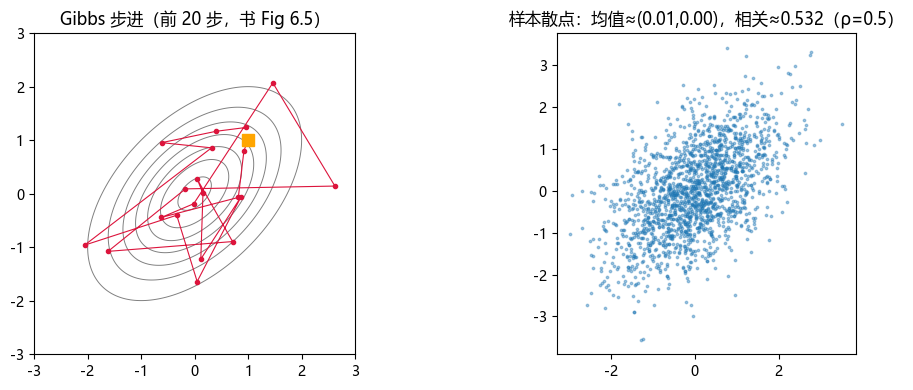

In [6]:
# ===== 书 §6.2 Alg 6.4 =====
rho = 0.5; var = 1 - rho**2
x, y = [1.0], [1.0]
for i in range(2000):
    x.append(rng.normal(rho*y[-1], np.sqrt(var)))   # X|Y
    y.append(rng.normal(rho*x[-1], np.sqrt(var)))   # Y|X（用最新 x）
x, y = np.array(x), np.array(y)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
# 等高线 + 步进
gx = np.linspace(-3, 3, 200); GX, GY = np.meshgrid(gx, gx)
Z = np.exp(-(GX**2 - 2*rho*GX*GY + GY**2)/(2*var))/(2*pi*np.sqrt(var))
ax[0].contour(GX, GY, Z, colors="0.5", linewidths=0.7)
ax[0].plot(x[:21], y[:21], "o-", ms=3, lw=0.8, color="crimson")
ax[0].plot(x[0], y[0], "s", color="orange", ms=8)
ax[0].set_title("Gibbs 步进（前 20 步，书 Fig 6.5）"); ax[0].set_aspect("equal")
ax[1].scatter(x[200:], y[200:], s=3, alpha=0.4)
ax[1].set_title(f"样本散点：均值≈({x[200:].mean():.2f},{y[200:].mean():.2f})，"
                f"相关≈{np.corrcoef(x[200:], y[200:])[0,1]:.3f}（ρ={rho}）")
ax[1].set_aspect("equal")
plt.tight_layout(); save(fig, "out-6-5.png"); plt.show()

## 实验 6 样本均值法求积 + 误差律（书 §6.3，式 (6.15)(6.17)）

\\(\\int_0^\\infty \\frac{dx}{(x+1)^2}=1\\)，采样密度 = 指数(0.1)。验证 O(n^{-1/2})。

n=1000: 估计 1.0428（真值 1，书误差 ~0.06%）


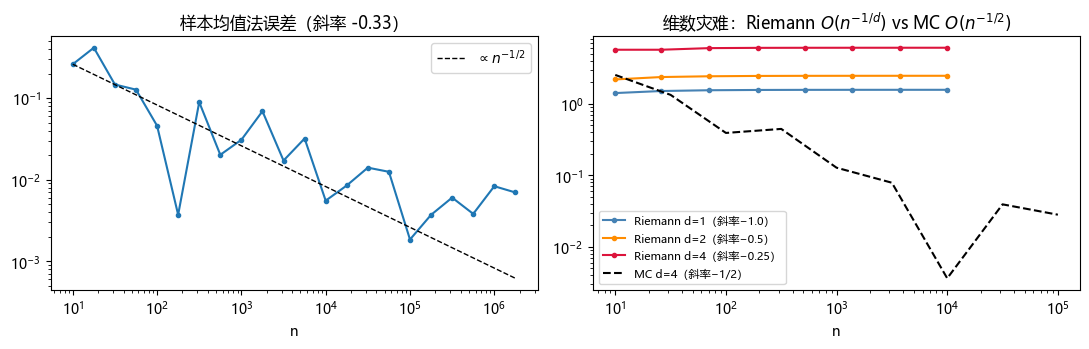

In [7]:
# ===== 书 §6.3 Alg 6.5 例 1 =====
lam = 0.1
def f1(x): return 1/(x+1)**2
def quad_mc(n):
    X = rng.exponential(1/lam, n)          # E(0.1)
    return np.mean(f1(X)/(lam*np.exp(-lam*X)))
est = quad_mc(1000)
print(f"n=1000: 估计 {est:.4f}（真值 1，书误差 ~0.06%）")
ns = 10**np.arange(1, 6.5, 0.25)
errs = [abs(quad_mc(int(n)) - 1) for n in ns]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].loglog(ns, errs, "o-", ms=3)
slope = np.polyfit(np.log(ns), np.log(errs), 1)[0]
ax[0].loglog(ns, errs[0]*(ns/ns[0])**(-0.5), "k--", lw=1, label=r"$\propto n^{-1/2}$")
ax[0].set_title(f"样本均值法误差（斜率 {slope:.2f}）"); ax[0].legend(); ax[0].set_xlabel("n")
# 维数灾难：Riemann vs MC
def f4d(v): return np.prod(np.cos(v)**2, axis=-1)      # 平滑试验函数
for d, c in [(1, "steelblue"), (2, "darkorange"), (4, "crimson")]:
    ns_r = np.unique(np.logspace(1, 4, 8).astype(int))
    errs_r = []
    for n in ns_r:
        m = max(1, int(round(n**(1/d))))
        grid = np.linspace(0, pi, m+1)[:-1]
        g = np.stack(np.meshgrid(*[grid]*d, indexing="ij"), axis=-1).reshape(-1, d)
        exact = pi**d/2**d
        errs_r.append(abs(f4d(g).mean()* (pi/m)**d - exact))
    ax[1].loglog(ns_r, errs_r, "o-", ms=3, color=c, label=f"Riemann d={d}（斜率−{1/d}）")
nsm = 10**np.arange(1, 5.5, 0.5)
em = [abs(np.mean(f4d(rng.uniform(0, pi, (int(n), 4))) * pi**4) - pi**4/16) for n in nsm]
ax[1].loglog(nsm, em, "k--", lw=1.5, label="MC d=4（斜率−1/2）")
ax[1].set_title(r"维数灾难：Riemann $O(n^{-1/d})$ vs MC $O(n^{-1/2})$")
ax[1].set_xlabel("n"); ax[1].legend(fontsize=8)
plt.tight_layout(); save(fig, "out-6-6.png"); plt.show()

## 实验 7 球体积（书 §6.3，Alg 6.6/6.7）

3D：\\(R=\\sqrt{U_1},\\ \\theta=\\tfrac\\pi2 U_2\\)（极坐标雅可比）；4D：\\(\\rho=U_1^{1/3},\\ \\phi=\\arccos(1-U_2),\\ \\theta=\\tfrac\\pi2 U_3\\)。

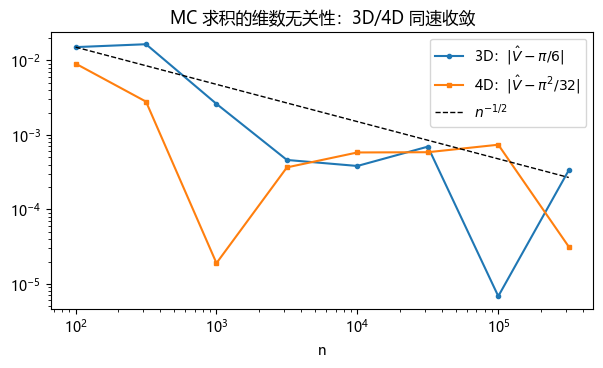

3D 估计 0.52274（π/6=0.52360）；4D 估计 0.30845（π²/32=0.30843）


In [8]:
# ===== 书 §6.3 球体积 =====
def vol3d(n):
    R, th = np.sqrt(rng.random(n)), rng.random(n)*pi/2
    x, y = R*np.cos(th), R*np.sin(th)
    return np.mean(np.sqrt(np.maximum(1-x*x-y*y, 0)))/(4/pi)   # /q 归一
def vol4d(n):
    r, phi, th = rng.random(n)**(1/3), np.arccos(1-rng.random(n)), rng.random(n)*pi/2
    x = r*np.sin(phi)*np.cos(th); y = r*np.sin(phi)*np.sin(th); z = r*np.cos(phi)
    # 球坐标采样保证球域内均匀（笛卡尔密度 q=6/π）；雅可比与参数密度相消：
    # E[f/q] = ∫f dV = (π/6)·E[f]（V(球一卦限)=π/6）
    return np.mean(np.sqrt(np.maximum(1-x*x-y*y-z*z, 0))) * pi/6
nsv = 10**np.arange(2, 6, 0.5)
e3 = [abs(vol3d(int(n)) - pi/6) for n in nsv]
e4 = [abs(vol4d(int(n)) - pi**2/32) for n in nsv]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.loglog(nsv, e3, "o-", ms=3, label=r"3D：$|\hat V-\pi/6|$")
ax.loglog(nsv, e4, "s-", ms=3, label=r"4D：$|\hat V-\pi^2/32|$")
ax.loglog(nsv, e3[0]*(nsv/nsv[0])**(-0.5), "k--", lw=1, label=r"$n^{-1/2}$")
ax.set_title("MC 求积的维数无关性：3D/4D 同速收敛"); ax.legend(); ax.set_xlabel("n")
save(fig, "out-6-7.png"); plt.show()
print(f"3D 估计 {vol3d(100000):.5f}（π/6={pi/6:.5f}）；4D 估计 {vol4d(100000):.5f}（π²/32={pi**2/32:.5f}）")

## 实验 8 控制变量（书 §6.3.1，Alg 6.8）

正态密度在 [−2,2] 的积分 ≈0.9545；柯西密度当控制变量（G=2/π·arctan2）。

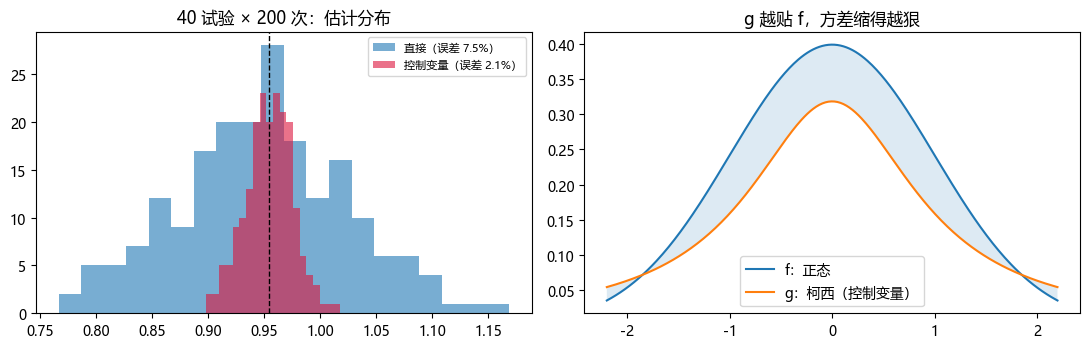

标准差对比：直接 0.0754 vs 控制变量 0.0210（缩减 3.6 倍）


In [9]:
# ===== 书 §6.3.1 Alg 6.8 =====
def normal_pdf(x): return np.exp(-x*x/2)/np.sqrt(2*pi)
def cauchy_pdf(x): return 1/(pi*(1+x*x))
G = 2/pi*np.arctan(2)                    # ∫Cauchy = 0.70483
def cv_trial(n):
    U = rng.uniform(-2, 2, n); q = 0.25
    direct = np.mean(normal_pdf(U)/q)
    cv = G + np.mean((normal_pdf(U)-cauchy_pdf(U))/q)
    return direct, cv
Nrep = 200
dirs = np.array([cv_trial(40)[0] for _ in range(Nrep)])
cvs = np.array([cv_trial(40)[1] for _ in range(Nrep)])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(dirs, bins=20, alpha=0.6, label=f"直接（误差 {np.std(dirs)*100:.1f}%）")
ax[0].hist(cvs, bins=20, alpha=0.6, color="crimson",
           label=f"控制变量（误差 {np.std(cvs)*100:.1f}%）")
ax[0].axvline(0.9545, color="k", ls="--", lw=1)
ax[0].set_title("40 试验 × 200 次：估计分布"); ax[0].legend(fontsize=8)
xs = np.linspace(-2.2, 2.2, 300)
ax[1].plot(xs, normal_pdf(xs), label="f：正态")
ax[1].plot(xs, cauchy_pdf(xs), label="g：柯西（控制变量）")
ax[1].fill_between(xs, cauchy_pdf(xs), normal_pdf(xs), alpha=0.15)
ax[1].set_title("g 越贴 f，方差缩得越狠"); ax[1].legend()
plt.tight_layout(); save(fig, "out-6-8.png"); plt.show()
print(f"标准差对比：直接 {np.std(dirs):.4f} vs 控制变量 {np.std(cvs):.4f}"
      f"（缩减 {np.std(dirs)/np.std(cvs):.1f} 倍）")

## 实验 9 重要性采样：2D 三角域（书 §6.3.1 例 2，Alg 6.10）

\\(\\int(1/\\sqrt{x^2+y^2}-1)=0.7627\\)；斜坡采样 \\(q_s=c(\\sqrt2-x-y)\\) vs 均匀。

2000 试验×100：均匀误差均值 6.4%，斜坡 4.4%（书 7%/5%）


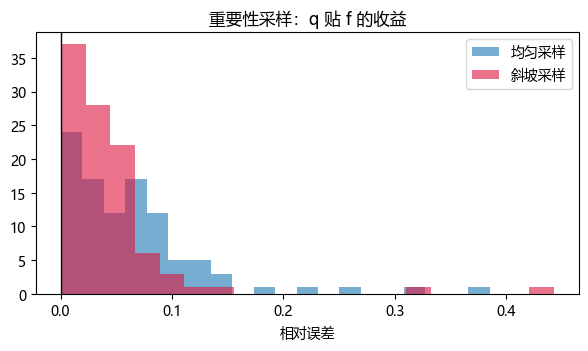

In [10]:
# ===== 书 §6.3.1 例 2 =====
S2 = np.sqrt(2); exact9 = 2*log(1+S2) - 1
def fcn9(x, y): return -1 + 1/np.sqrt(x*x + y*y)
def samp_unif(n):
    u1, u2 = rng.random(n), rng.random(n)
    return S2*(1-np.sqrt(u1)), (S2 - S2*(1-np.sqrt(u1)))*u2
def samp_slant(n):                       # 书 Fig 6.13 反演
    u1, u2 = rng.random(n), rng.random(n)
    X = S2*(1 - u1**(1/3)); Y = (S2 - X)*(1 - np.sqrt(u2))  # 指数 1/3（书代码 0.334 同）
    return X, Y
def trial(n, slant):
    if slant:
        X, Y = samp_slant(n)
        q = (6/2**1.5)*(S2 - X - Y)
    else:
        X, Y = samp_unif(n); q = np.ones(n)
    return np.mean(fcn9(X, Y)/q)
errs_u = [abs(trial(2000, False)-exact9)/exact9 for _ in range(100)]
errs_s = [abs(trial(2000, True)-exact9)/exact9 for _ in range(100)]
print(f"2000 试验×100：均匀误差均值 {np.mean(errs_u):.1%}，斜坡 {np.mean(errs_s):.1%}（书 7%/5%）")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(errs_u, bins=20, alpha=0.6, label="均匀采样")
ax.hist(errs_s, bins=20, alpha=0.6, color="crimson", label="斜坡采样")
ax.axvline(0, color="k", lw=1); ax.set_xlabel("相对误差")
ax.set_title("重要性采样：q 贴 f 的收益"); ax.legend()
save(fig, "out-6-9.png"); plt.show()

## 实验 10 MCMC 求积（书 §6.3.2，Alg 6.12）

只给非负 \\(\\hat q=\\sqrt2-x-y\\)（不归一、不反演），Metropolis 采样 + 均匀采样估 Q。

Q 估计 0.4723（精确 2^1.5/6=0.4714）
MCMC 求积估计 0.7708，误差 1.1%（书 ~1.6%，20 万试验）


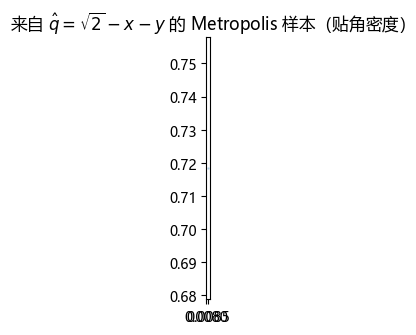

In [11]:
# ===== 书 §6.3.2 Alg 6.12 =====
delta = 0.1
def mcmc_xy(x, y):
    while True:
        xn = abs(x - delta + 2*delta*rng.random())
        yn = abs(y - delta + 2*delta*rng.random())
        if xn + yn <= S2: break
    h_new, h_old = S2-xn-yn, S2-x-y
    if rng.random() < h_new/h_old: x, y = xn, yn
    return x, y
nT = 200_000
xp = yp = 0.7; acc = 0.0; Q = 0.0
Xu, Yu = samp_unif(nT)
Q = np.mean((S2 - Xu - Yu)/1.0)          # 均匀密度=1 估计 Q
for i in range(nT):
    xp, yp = mcmc_xy(xp, yp)
    acc += fcn9(xp, yp)/(S2-xp-yp)
est = Q*acc/nT
print(f"Q 估计 {Q:.4f}（精确 2^1.5/6={2**1.5/6:.4f}）")
print(f"MCMC 求积估计 {est:.4f}，误差 {abs(est-exact9)/exact9:.1%}（书 ~1.6%，20 万试验）")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.scatter(xp, yp, s=1, alpha=0.2)
ax.set_title(r"来自 $\hat q=\sqrt{2}-x-y$ 的 Metropolis 样本（贴角密度）")
ax.set_aspect("equal")
save(fig, "out-6-10.png"); plt.show()

## 实验 11 舍入误差（书 §6.4，Fig 6.14）

float32 的样本均值：误差先按 n^{-1/2} 降、n≈2×10⁷ 后反弹（大数吃小数）。

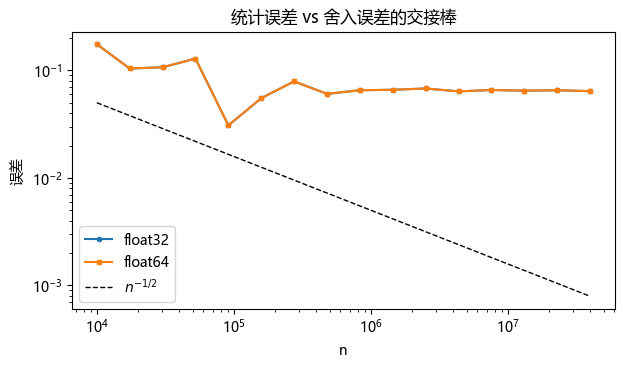

float32 拐点 ≈ n=91,201（误差 3.08e-02），此后反弹


In [12]:
# ===== 书 §6.4 Fig 6.14 =====
def f2(x): return -2 + (x-2)**2 + 1/np.sqrt(x)   # 书的试验函数
ns = np.unique(np.logspace(4, 7.6, 16).astype(int))
errs32, errs64 = [], []
for n in ns:
    x = rng.uniform(1e-3, 4, n)
    exact = 4/3
    errs32.append(abs(np.float32(np.sum(np.float32(4*f2(x))))/np.float32(n) - exact))
    errs64.append(abs(np.mean(4*f2(x)) - exact))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.loglog(ns, errs32, "o-", ms=3, label="float32")
ax.loglog(ns, errs64, "s-", ms=3, label="float64")
ax.loglog(ns, 0.05*(ns/ns[0])**(-0.5), "k--", lw=1, label=r"$n^{-1/2}$")
ax.set_xlabel("n"); ax.set_ylabel("误差"); ax.set_title("统计误差 vs 舍入误差的交接棒")
ax.legend(); save(fig, "out-6-11.png"); plt.show()
i = int(np.argmin(errs32))
print(f"float32 拐点 ≈ n={ns[i]:,}（误差 {errs32[i]:.2e}），此后反弹")